# Step 4 – Forecast targets and feature engineering

Plan reference: `schneider_problem1_plan.md`, Step 4. The logic is in `src/`:

| Module | Role |
|---|---|
| `src/external_data.py` | downloads the free external series (GSCPI, EPU, EIA STEO, Ember EUA) |
| `src/features.py` | builds every candidate feature from data known at the origin, and the leakage checks |
| `src/feature_selection.py` | evidence (PACF, lead-lag, Granger, backtest, sign) and the selection |
| `src/feature_plots.py` | charts |
| `configs/features.yaml` | the feature catalogue: definition, reason, expected sign and delay |

Run order from a clean clone: `src.data_prep` → `src.external_data` → `src.features` → `src.feature_selection`.
The written report is `report/problem1/step4_features.md`.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
# The pipeline uses paths relative to the repo root (Data/, configs/).
if Path.cwd().name == "analysis":
    os.chdir("..")
import numpy as np
import pandas as pd
from IPython.display import display

from src import features as F, feature_selection as FS, feature_plots as FP
from src.external_data import load_external

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
FP.set_style()

cfg = F.load_config()
inputs = F.load_inputs()
TARGETS, H = list(cfg["targets"]), cfg["settings"]["horizons"]
TABLES = Path("report") / "problem1" / "step4_tables"
TABLES.mkdir(parents=True, exist_ok=True)

def save(df, name, index=False):
    df.to_csv(TABLES / f"{name}.csv", index=index)
    return df

## 4.1 What we forecast

The 15 targets come from Step 1 (`data_dictionary.csv`): the priceable BOM proxies plus epoxy.
For each one we model `y = log(P[o+H]) − log(P[o])` with one model per horizon H = 3, 6, 9 months.

In [2]:
d = pd.read_csv("Data/processed/data_dictionary.csv", index_col=0)
tg = d[d["forecast_target"]][["description", "unit", "source", "lag_months", "target_region", "first_month", "last_month"]]
display(tg)

,description,unit,source,lag_months,target_region,first_month,last_month
S01,"Copper, grade A cathode, LME – global price",USD/t,IMF via FRED,2,WW,2016-11-01,2026-09-01
S02,"Aluminium 99.5% min, LME – global price",USD/t,IMF via FRED,2,WW,2016-11-01,2026-09-01
S03,"Nickel, LME – global price",USD/t,IMF via FRED,2,WW,2016-11-01,2026-09-01
S04,Iron ore fines 62% Fe CFR China,USD/dmt,IMF via FRED,2,WW,2016-11-01,2026-09-01
S05,"Zinc, LME – global price",USD/t,IMF via FRED,2,WW,2016-11-01,2026-09-01
S07,Producer price index – Copper production (NACE...,Index 2021=100,Eurostat PPI,2,EU,2016-11-01,2026-09-01
S08,Producer price index – Aluminium production (N...,Index 2021=100,Eurostat PPI,2,EU,2016-11-01,2026-09-01
S09,Producer price index – Basic iron & steel and ...,Index 2021=100,Eurostat PPI,2,EU,2016-11-01,2026-09-01
S10,Producer price index – Basic iron & steel (NAC...,Index 2021=100,Eurostat PPI,2,EU,2016-11-01,2026-09-01
S11,Producer price index – Plastics in primary for...,Index 2021=100,Eurostat PPI,2,EU,2016-11-01,2026-09-01


## External data

Downloaded by `src/external_data.py` (cached in `Data/external/`).

In [3]:
ext, steo, ext_sources = load_external()
display(ext_sources[["series_id", "source", "licence", "lag", "first_month", "last_month"]])
save(ext_sources.drop(columns=["url"]), "external_sources")
print("STEO releases:", steo["release_month"].nunique(), "from", steo["release_month"].min().date(), "to", steo["release_month"].max().date())

,series_id,source,licence,lag,first_month,last_month
0,GSCPI,Federal Reserve Bank of New York,Free to use with attribution (NY Fed website t...,3,1998-01,2026-10
1,EPU_GLOBAL,"Baker, Bloom & Davis – policyuncertainty.com","Free to use, cite Baker, Bloom & Davis (2016) ...",4,1997-01,2026-07
2,EPU_EUROPE,"Baker, Bloom & Davis – policyuncertainty.com","Free to use, cite Baker, Bloom & Davis (2016)",1,1997-01,2026-10
3,EPU_US,"Baker, Bloom & Davis – policyuncertainty.com","Free to use, cite Baker, Bloom & Davis (2016)",1,1997-01,2026-10
4,EUA_EUR,Ember – Carbon Price Viewer ('ETS prices – EU ...,CC BY 4.0 (Ember),1,2018-01,2026-09
5,STEO,US Energy Information Administration,"Public domain (US government work), attributio...",0,2016-11,2026-10


STEO releases: 120 from 2016-11-01 to 2026-10-01


## Timing rule: what is known at the origin

At origin *o* (the last known month of the target), the forecast is made at the start of month *o + 2*.
A series with publication lag *L* is known up to month *o + 2 − L*, and never after *o*.
Example: the submission origin, September 2026.

In [4]:
known = F.info_set(inputs, "2026-09", cfg["settings"]["quote_gap_months"])
last = known.apply(lambda s: s.last_valid_index())
ex = pd.DataFrame({"lag_months": inputs.lags, "last_month_known": last.dt.strftime("%Y-%m")})
display(ex.loc[["S01", "D01", "S09", "S11", "EPOXY_EUR", "MEPS_DE_HR", "LME_CU_STOCKS",
                "CRU_SS304_DE_BASE", "ED01", "GSCPI", "EPU_GLOBAL", "EPU_EUROPE", "EUA_EUR"]])

,lag_months,last_month_known
S01,2,2026-09
D01,2,2026-09
S09,2,2026-09
S11,2,2026-09
EPOXY_EUR,1,2026-09
MEPS_DE_HR,1,2026-09
LME_CU_STOCKS,1,2026-09
CRU_SS304_DE_BASE,3,2026-08
ED01,2,2026-09
GSCPI,3,2026-08


## 4.4 Proof that every feature was known at forecast time

Two checks:
1. **Rule table**: for every target, feature and two sample origins, the last month of data used must be on or before the latest month allowed by the publication lag.
2. **Poisoned-future test**: every value that was *not* known at the origin is replaced by random numbers (and every later STEO release too). The features must not change.

In [5]:
proof = F.known_at_forecast_time(inputs, cfg, ["2022-06", "2026-09"])
print(f"{len(proof)} rows, all rule checks passed: {proof['rule_ok'].all()}")
save(proof, "known_at_forecast_time")
display(proof[proof["origin"] == "2026-09"].drop_duplicates("series")
        [["series", "source", "lag_months", "latest_allowed", "last_month_used", "rule_ok"]].sort_values("lag_months"))

286 rows, all rule checks passed: True


,series,source,lag_months,latest_allowed,last_month_used,rule_ok
257,STEO brent,US Energy Information Administration,0,2026-09,STEO release 2026-09,True
275,STEO wti,US Energy Information Administration,0,2026-09,STEO release 2026-09,True
159,S06,ECB,1,2026-09,2026-09,True
148,LME_CU_SPREAD_EUR,LME (Westmetall),1,2026-09,2026-09,True
190,EUA_EUR,Ember – Carbon Price Viewer ('ETS prices – EU ...,1,2026-09,2026-09,True
177,LME_AL_STOCKS,LME (Westmetall),1,2026-09,2026-09,True
176,LME_AL_SPREAD_EUR,LME (Westmetall),1,2026-09,2026-09,True
149,LME_CU_STOCKS,LME (Westmetall),1,2026-09,2026-09,True
222,MEPS_DE_HDG,MEPS,1,2026-09,2026-09,True
246,E09,Ember,1,2026-09,2026-09,True


In [6]:
poison = F.poisoned_future_test(inputs, cfg, n=12, seed=0)
save(poison, "poisoned_future_test")
print(f"{len(poison)} cases (12 random origins × 15 targets × 3 horizons), "
      f"features unchanged in all: {poison['features_unchanged'].all()}")
display(poison.groupby("origin")[["n_hidden_values_poisoned", "features_unchanged"]].agg({"n_hidden_values_poisoned": "first", "features_unchanged": "all"}))

540 cases (12 random origins × 15 targets × 3 horizons), features unchanged in all: True


,n_hidden_values_poisoned,features_unchanged
origin,,
2018-07,8723,True
2018-09,8545,True
2019-01,8189,True
2019-11,7299,True
2020-06,6676,True
2020-10,6320,True
2022-04,4718,True
2023-03,3739,True
2023-10,3116,True


## Feature tables

One table per target and horizon: rows = origins, columns = candidate features and `y`.

In [7]:
tables = F.build_tables(inputs, cfg)
F.FEATURE_DIR.mkdir(parents=True, exist_ok=True)
for (t, h), df in tables.items():
    df.to_csv(F.FEATURE_DIR / f"{t}_h{h}.csv")
sizes = pd.DataFrame([{"target": t, "horizon": h, "rows": len(df), "rows_with_y": int(df["y"].notna().sum()),
                       "first_origin": df.index[0].strftime("%Y-%m"), "candidates": df.shape[1] - 2}
                      for (t, h), df in tables.items()])
display(sizes.pivot(index="target", columns="horizon", values="rows_with_y").reindex(TARGETS))
display(tables[("S09", 3)].tail(3))

horizon,3,6,9
target,,,
S01,104,101,98
D01,104,101,98
S07,104,101,98
S02,104,101,98
D02,104,101,98
S08,104,101,98
S03,104,101,98
S04,104,101,98
S05,104,101,98


,own_chg_1m,own_chg_3m,own_vs_12m_avg,own_pos_12m_range,own_vol_12m,meps_hr_chg_1m,steel_gap_3m_s09,iron_ore_eur_chg_3m,nickel_eur_chg_1m,ttf_chg_3m,eua_chg_3m,gscpi,y,target_month
origin,,,,,,,,,,,,,,
2026-07-01,0.011,0.031,0.054,1.0,0.010,-0.007,-0.068,-0.049,-0.047,0.178,0.091,1.203,NaN,2026-10-01
2026-08-01,0.004,0.019,0.051,1.0,0.009,0.037,-0.019,-0.107,-0.008,0.266,0.077,0.951,NaN,2026-11-01
2026-09-01,0.003,0.017,0.047,1.0,0.008,0.029,0.041,-0.032,-0.019,0.525,0.082,1.271,NaN,2026-12-01


## Candidate catalogue (from `configs/features.yaml`)

In [8]:
cat = []
for name, s in cfg["own_features"].items():
    cat.append({"feature": name, "group": "own price", "definition": s["label"], "expected_sign": s["sign"], "delay": s["delay"], "used_for": "all targets"})
for name, s in cfg["drivers"].items():
    users = [t for t, v in cfg["targets"].items() if name in v["drivers"]]
    cat.append({"feature": name, "group": "driver", "definition": s["label"], "expected_sign": s["sign"], "delay": s["delay"], "used_for": ", ".join(users)})
cat = save(pd.DataFrame(cat), "candidate_catalogue")
display(cat)

,feature,group,definition,expected_sign,delay,used_for
0,own_chg_1m,own price,Change of the price over the last month,+,1 month,all targets
1,own_chg_3m,own price,Change of the price over the last 3 months,+,1-3 months,all targets
2,own_vs_12m_avg,own price,Price compared with its own 12-month average (...,-,3-9 months,all targets
3,own_pos_12m_range,own price,Position of the price between its 12-month low...,-,3-9 months,all targets
4,own_vol_12m,own price,Volatility of monthly price changes over the l...,0,none,all targets
5,cu_spread,driver,"LME copper 3-month price minus cash price, as ...",-,1-3 months,"S01, D01, S07"
6,cu_stocks_chg_3m,driver,Change of LME copper warehouse stocks over 3 m...,-,1-3 months,"S01, D01"
7,al_spread,driver,"LME aluminium 3-month price minus cash price, ...",-,1-3 months,"S02, D02"
8,al_stocks_chg_3m,driver,Change of LME aluminium warehouse stocks over ...,-,1-3 months,"S02, D02"
9,eurusd_chg_3m,driver,Change of the euro against the dollar over 3 m...,-,0-3 months,"D01, D02"


## 4.2 Own-price lags: ACF / PACF and seasonality

Selection window only (up to the hold-out start).

,target,pacf,band,own_chg_1m_candidate,significant_pacf_lags
0,S01,0.266,0.196,True,"1, 5, 6, 8"
1,D01,0.204,0.196,True,"1, 3, 5, 6, 8, 10"
2,S07,0.101,0.196,False,"5, 8, 10"
3,S02,0.379,0.196,True,"1, 2"
4,D02,0.355,0.196,True,"1, 2"
5,S08,0.709,0.196,True,"1, 3, 11"
6,S03,0.323,0.196,True,"1, 4"
7,S04,0.246,0.196,True,"1, 4, 7"
8,S05,0.111,0.196,False,none
9,S09,0.789,0.196,True,1


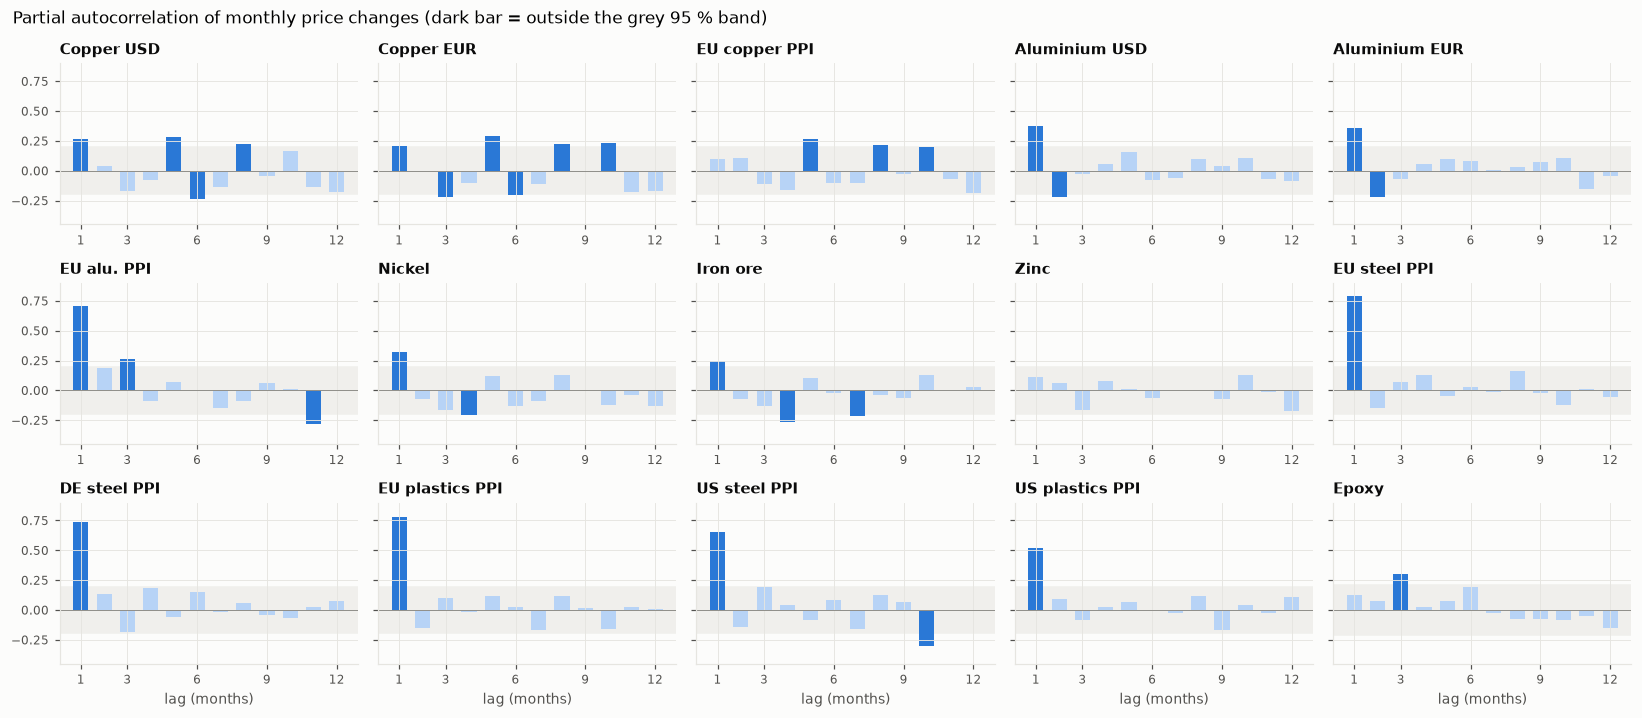

In [9]:
res = FS.run_selection(inputs.data, tables, cfg)
save(res["acf_pacf"], "acf_pacf")
display(save(res["own_lag_decision"].reset_index(), "own_lag_decision"))
FP.pacf_grid(res["acf_pacf"]);

In [10]:
display(save(res["seasonality"].reset_index(), "seasonality"))

,target,p_value,p_holm,calendar_features
0,S01,0.916,1.000,False
1,D01,0.779,1.000,False
2,S07,0.711,1.000,False
3,S02,0.714,1.000,False
4,D02,0.466,1.000,False
5,S08,0.935,1.000,False
6,S03,0.905,1.000,False
7,S04,0.048,0.714,False
8,S05,0.584,1.000,False
9,S09,0.472,1.000,False


## 4.3 Evidence for each candidate

Lead–lag (rank correlation with the H-month change), Granger tests with Holm correction, backtest gain, sign check.

In [11]:
gr = save(res["granger"], "granger")
display(gr.sort_values("granger_p_holm").head(20))

,target,feature,n,granger_p,granger_p_holm
24,S08,d02_chg_1m,89,1.664e-12,1.082e-10
25,S08,al_gap_3m,89,1.207e-11,7.726e-10
62,EPOXY_EUR,brent_eur_chg_1m,75,3.963e-06,2.497e-04
38,S09,meps_hr_chg_1m,89,1.159e-05,7.185e-04
51,S11,brent_eur_chg_1m,89,4.918e-05,3.000e-03
10,S07,cu_gap_3m,89,5.053e-05,3.032e-03
59,S13,wti_chg_1m,89,6.840e-05,4.036e-03
40,S09,iron_ore_eur_chg_3m,89,2.094e-04,1.214e-02
9,S07,d01_chg_1m,89,2.617e-04,1.492e-02
39,S09,steel_gap_3m_s09,89,5.702e-04,3.193e-02


In [12]:
ev = res["evidence"]
cols = ["target", "horizon", "feature", "group", "sign_expected", "spearman", "band", "granger_p_holm",
        "stat_signal", "gain_alone", "gain_when_added", "coef_median_std", "decision", "reason"]
ev = save(ev[cols], "evidence")
display(ev[ev["target"] == "S09"])

,target,horizon,feature,group,sign_expected,spearman,band,granger_p_holm,stat_signal,gain_alone,gain_when_added,coef_median_std,decision,reason
249,S09,3,own_chg_1m,own,+,0.704,0.366,NaN,NaN,-0.196,-0.196,0.038,kept,NaN
250,S09,3,own_chg_3m,own,+,0.626,0.366,NaN,NaN,-0.109,NaN,NaN,dropped,does not lower the backtest loss by 1 % once b...
251,S09,3,own_vs_12m_avg,own,-,0.487,0.366,NaN,NaN,-0.147,NaN,NaN,dropped,does not lower the backtest loss by 1 % once b...
252,S09,3,own_pos_12m_range,own,-,0.569,0.366,NaN,NaN,-0.171,-0.062,NaN,shortlist,won forward selection but not robust: tested l...
253,S09,3,own_vol_12m,own,0,0.038,0.366,NaN,NaN,0.485,NaN,NaN,dropped,does not lower the backtest loss by 1 % once b...
254,S09,3,meps_hr_chg_1m,driver,+,0.510,0.366,7.185e-04,True,0.122,NaN,NaN,dropped,does not lower the backtest loss by 1 %
255,S09,3,steel_gap_3m_s09,driver,+,0.283,0.366,3.193e-02,True,0.343,NaN,NaN,dropped,does not lower the backtest loss by 1 %
256,S09,3,iron_ore_eur_chg_3m,driver,+,0.379,0.366,1.214e-02,True,-0.055,NaN,NaN,dropped,does not lower the backtest loss by 1 %
257,S09,3,nickel_eur_chg_1m,driver,+,0.294,0.366,1.000e+00,False,-0.007,NaN,NaN,dropped,no statistical signal (Granger and lead-lag bo...
258,S09,3,ttf_chg_3m,driver,+,0.503,0.366,1.000e+00,True,0.069,NaN,NaN,dropped,does not lower the backtest loss by 1 %


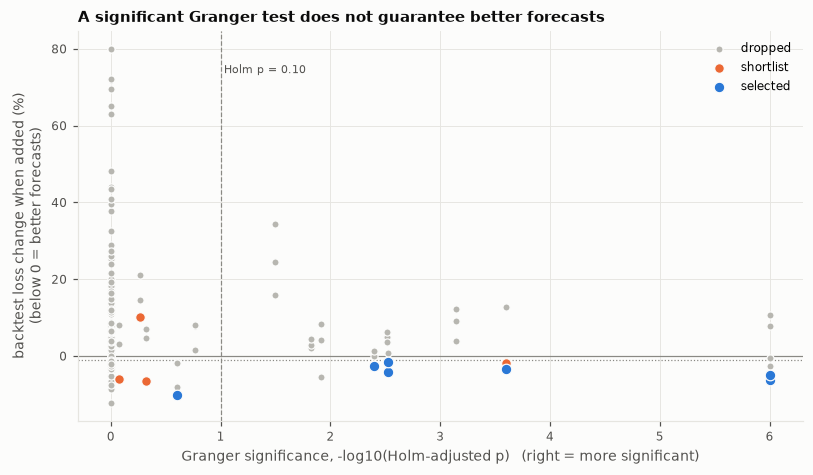

In [13]:
FP.significance_vs_gain(ev);

## Selected features, robustness and business effects

In [14]:
rob = FS.robustness(tables, cfg, res["selected"])
eff = FS.effects(tables, cfg, res["selected"])
final = rob.merge(eff, on=["target", "horizon", "feature"])
display(save(final, "selected_features_detail"))
sel = pd.DataFrame([{"target": t, "horizon": h, "selected": ", ".join(f) or "(none: historical quantiles)",
                     "shortlist_only": ", ".join(x for x in res["shortlist"][(t, h)] if x not in f)}
                    for (t, h), f in res["selected"].items()])
display(save(sel, "selected_features"))

,target,horizon,feature,gain_added_last,p_helps,n_eval,gain_added_last_early_window,typical_move,effect_p10_pct,effect_p50_pct,effect_p90_pct,latest_value,n_train
0,D01,3,own_pos_12m_range,-0.035,0.974,38,-0.033,0.368,-4.382,0.000,1.595,1.000,86
1,D02,9,own_chg_1m,-0.050,1.000,32,-0.049,0.046,-1.299,3.174,10.186,0.017,80
2,S08,3,own_chg_1m,-0.236,0.977,38,-0.199,0.017,1.134,2.776,4.417,-0.004,86
3,S08,3,d02_chg_1m,-0.063,0.907,38,-0.034,0.046,1.122,1.504,0.598,0.017,86
4,S08,6,own_chg_1m,-0.192,0.814,35,-0.006,0.018,2.471,6.530,10.396,-0.004,83
5,S08,9,d02_chg_1m,-0.079,0.998,32,-0.077,0.046,2.176,3.743,9.063,0.017,80
6,S03,3,own_chg_3m,-0.098,0.959,38,-0.148,0.164,-3.986,-7.889,-4.080,-0.075,86
7,S03,3,own_chg_1m,-0.080,0.977,38,-0.037,0.078,1.336,8.091,5.688,-0.026,86
8,S04,6,own_chg_3m,-0.081,1.000,35,-0.049,0.203,-16.136,-7.268,-0.572,-0.033,83
9,S05,6,own_chg_3m,-0.053,0.999,35,-0.070,0.117,-6.864,2.839,0.000,0.128,83


,target,horizon,selected,shortlist_only
0,S01,3,(none: historical quantiles),
1,S01,6,(none: historical quantiles),
2,S01,9,(none: historical quantiles),
3,D01,3,own_pos_12m_range,
4,D01,6,(none: historical quantiles),own_chg_1m
5,D01,9,(none: historical quantiles),
6,S07,3,(none: historical quantiles),own_chg_3m
7,S07,6,(none: historical quantiles),
8,S07,9,(none: historical quantiles),
9,S02,3,(none: historical quantiles),own_vs_12m_avg


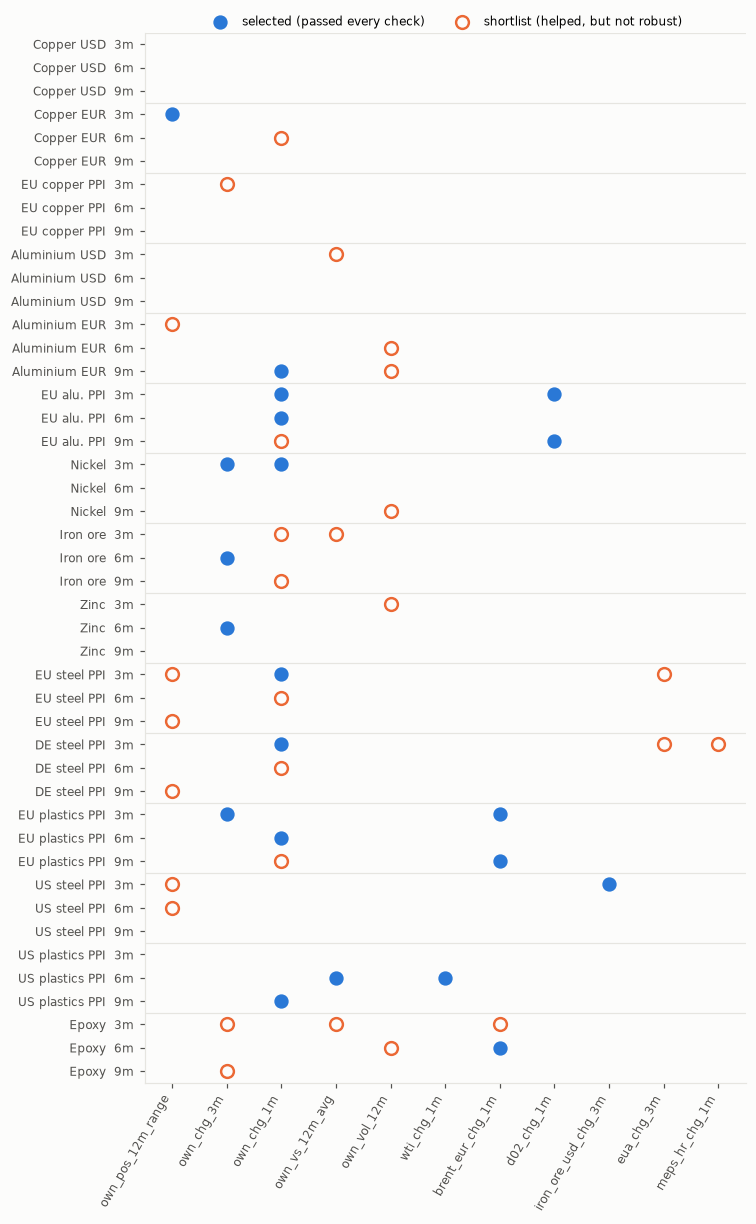

In [15]:
FP.selection_matrix(ev, TARGETS, H);

,target,horizon,n_features,features,loss_hist_quantiles,loss_selected,gain_vs_hist_quantiles
0,S01,3,0,,0.024,0.024,0.000
1,S01,6,0,,0.036,0.036,0.000
2,S01,9,0,,0.039,0.039,0.000
3,D01,3,1,own_pos_12m_range,0.020,0.020,-0.035
4,D01,6,0,,0.027,0.027,0.000
5,D01,9,0,,0.032,0.032,0.000
6,S07,3,0,,0.014,0.014,0.000
7,S07,6,0,,0.018,0.018,0.000
8,S07,9,0,,0.019,0.019,0.000
9,S02,3,0,,0.030,0.030,0.000


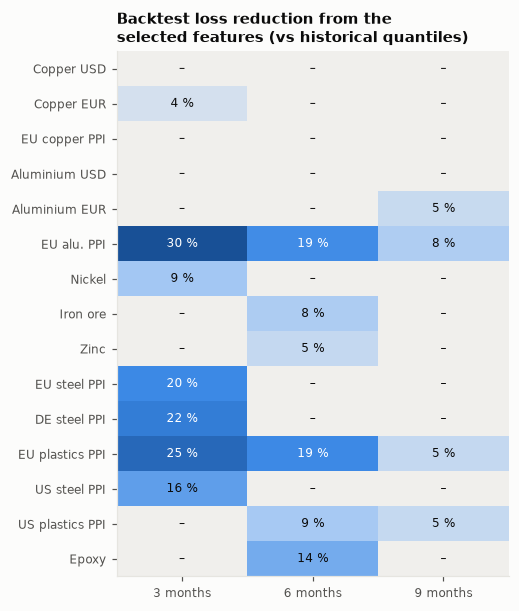

In [16]:
display(save(res["skill"], "skill"))
FP.skill_heatmap(res["skill"], TARGETS, H);

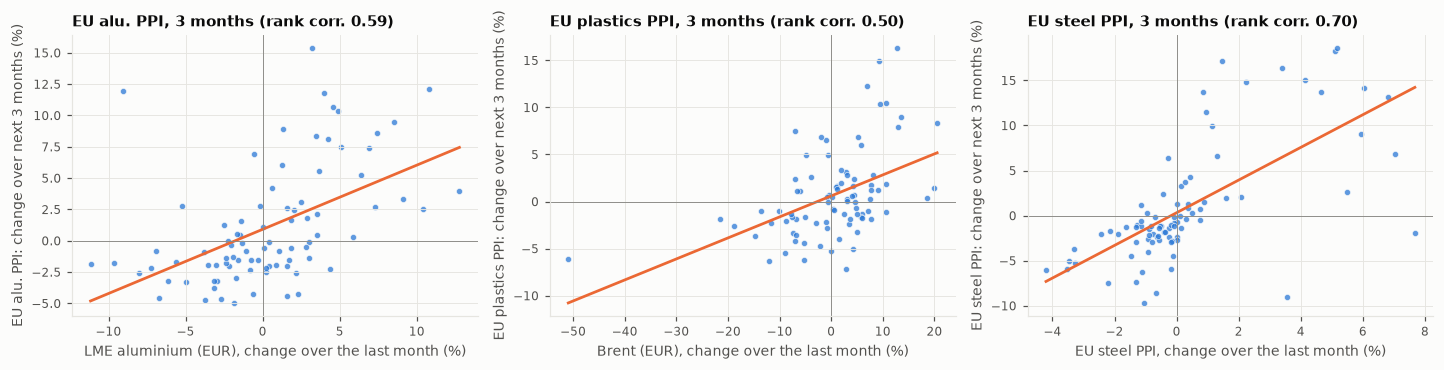

In [17]:
FP.driver_examples(tables, [
    ("S08", 3, "d02_chg_1m", "LME aluminium (EUR), change over the last month (%)"),
    ("S11", 3, "brent_eur_chg_1m", "Brent (EUR), change over the last month (%)"),
    ("S09", 3, "own_chg_1m", "EU steel PPI, change over the last month (%)"),
], cfg["selection"]["select_end"]);

## For Step 7

The selection above uses data up to the hold-out start (`select_end`). In a rolling backtest the selection must be
redone inside each fold, with `FS.run_selection(data, tables, cfg, end=<fold origin>)`, otherwise the backtest
reuses information from later folds.